# Lab 3 — Millions of TVs, Who Is Watching?
Name: Vladislav | Group: KM_43

## Setup

In [1]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])

In [2]:
for name, df in [("acr_sessions", acr_sessions), ("hh_attributes", hh_attributes),
                 ("reference_ratings", reference_ratings)]:
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Sessions from", acr_sessions["start_utc"].min(), "to", acr_sessions["start_utc"].max())
display(acr_sessions.head())
display(hh_attributes.head())

acr_sessions: 6,392,981 rows x 9 columns
hh_attributes: 54,314 rows x 8 columns
reference_ratings: 8 rows x 2 columns
Sessions from 2024-10-14 10:00:00+00:00 to 2024-10-28 09:59:58+00:00


,session_id,tv_id,hashed_ip,session_type,network_code,input_source,start_utc,end_utc,dma_code
0,900000001,7000070,ab52471d5e819372,live,AE,cable_box,2024-10-14 10:00:00+00:00,2024-10-14 10:12:45+00:00,512
1,900000002,7001293,40b3ee0f735e5d6f,live,NICK,satellite_box,2024-10-14 10:00:00+00:00,2024-10-14 10:02:46+00:00,819
2,900000003,7002192,205e67ce16ecae41,live,TBS,streaming_device,2024-10-14 10:00:00+00:00,2024-10-14 10:20:46+00:00,539
3,900000004,7002576,eb3a1cc402f76418,live,USA,cable_box,2024-10-14 10:00:00+00:00,2024-10-14 10:17:00+00:00,532
4,900000005,7004550,8ce7ccf88d91472c,live,DSNY,cable_box,2024-10-14 10:00:00+00:00,2024-10-14 10:30:00+00:00,539


,household_id,hashed_ip,region,income_band,head_age_band,hh_size,children,new_car_intender_6mo
0,83984053,36af94746d33cd86,Midwest,$100k-$150k,65+,5,True,0.093
1,92383868,1abf63dfd44fe16a,South,$25k-$50k,65+,1,False,0.033
2,63791521,630b61873c401b13,West,$100k-$150k,18-34,4,True,0.188
3,85357721,06a1fa5e0fc97e52,South,$150k+,18-34,5,True,0.274
4,52698528,754a63ab6fa0db9e,South,$100k-$150k,50-64,5,True,0.214


### Rules and helpers
Times are converted to US Eastern, a session belongs to the broadcast day (06:00-05:59) of its start.
Sessions shorter than 1 minute are dropped. A TV is in-tab on a day if it has at least one session left.
A TV or panel household watched a telecast if its live sessions on that network overlap it by at least
1 minute in total. The panel yardstick is the Lab 1 H records in-tab on October 14-27, each with its
average weight over its in-tab days.

In [3]:
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]
NETWORKS = BIG + SMALL
D0, D1 = pd.Timestamp("2024-10-14"), pd.Timestamp("2024-10-27")


def broadcast_date(ts):
    return (ts - pd.Timedelta(hours=6)).dt.normalize()


def watchers(sessions, net, start, end, id_col):
    # ids whose sessions on net overlap the telecast by >= 1 minute in total
    x = sessions[(sessions["network_code"] == net) & (sessions["start_ts"] < end) & (sessions["end_ts"] > start)]
    ov = (x["end_ts"].clip(upper=end) - x["start_ts"].clip(lower=start)).dt.total_seconds() / 60
    tot = ov.groupby(x[id_col]).sum()
    return tot.index[tot >= 1]


acr = acr_sessions.copy()
acr["start_ts"] = acr["start_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["end_ts"] = acr["end_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["minutes"] = (acr["end_ts"] - acr["start_ts"]).dt.total_seconds() / 60
acr["bdate"] = broadcast_date(acr["start_ts"])
acr_ok = acr[acr["minutes"] >= 1].copy()  # edit rule
live = acr_ok[acr_ok["session_type"] == "live"]

intab_tv = acr_ok.groupby("bdate")["tv_id"].nunique()

# panel yardstick: H records, average weight over Oct 14-27
dw_h = daily_weights[(daily_weights["resp_type"] == "H")
                     & daily_weights["broadcast_date"].between(D0, D1)]
panel_hh = dw_h.groupby("respondent_id")["weight"].mean().rename("w").reset_index()
intab_panel_n = dw_h.groupby("broadcast_date")["respondent_id"].nunique()
intab_panel_w = dw_h.groupby("broadcast_date")["weight"].sum()

va = viewer_attributes.merge(attributes, on="attr_id", how="left")


def attr_col(group):
    x = va[va["attr_group"] == group][["respondent_id", "attr_name"]]
    return x.set_index("respondent_id")["attr_name"]


panel_hh["region"] = panel_hh["respondent_id"].map(attr_col("Census region"))
panel_hh["income_band"] = panel_hh["respondent_id"].map(attr_col("Household income"))

# age of the head of household in the panel
head = va[va["attr_id"] == 701]["respondent_id"]
age = va[va["attr_id"] == 300].set_index("respondent_id")["value"]
head_age = pd.Series(age.reindex(head).values, index=(head // 100 * 100).values)
head_age = head_age[~head_age.index.duplicated()]
panel_hh["head_age_band"] = pd.cut(panel_hh["respondent_id"].map(head_age),
                                   [17, 34, 49, 64, 200], labels=["18-34", "35-49", "50-64", "65+"]).astype(str)

pv_h = viewings[(viewings["resp_type"] == "H")].copy()
pv_h["bdate"] = broadcast_date(pv_h["start_ts"])
pv_h = pv_h[pv_h["bdate"].between(D0, D1)]
print("Panel households in-tab Oct 14-27:", len(panel_hh))
print("Panel H weight per day (M):", round(intab_panel_w.mean() / 1e6, 1))

Panel households in-tab Oct 14-27: 4111
Panel H weight per day (M): 125.8


## Task 1.1 — Five questions

| Question | acr_sessions (smart-TV feed) | Lab 1 viewings (panel) |
|---|---|---|
| Grain | one session of continuous viewing of one thing on one smart TV (ends on network / program / input change) | one viewing session of one person (R, L, S) or one household's set (H) on one of ten networks |
| Key | session_id; the TV is tv_id, linked to households only through hashed_ip | viewing_id; person = respondent_id, household = respondent_id // 100 |
| Coverage | 29,940 opted-in smart TVs of one maker, one set per home, any US network plus apps / devices, Oct 14–27 | ~4,000 recruited households, every set in the home, only the ten networks, Oct 1–31 |
| Weight | none: every TV counts once (unweighted) | daily weight per household / person, sums to 125.8 M US TV households and 317.3 M persons |
| Provenance | automatic content recognition on the TV (screen fingerprint matched to live feeds), demographics bought from a compiled / modeled consumer file | people-meter panel run by a measurement service: probability recruitment, persons log in, demographics asked directly |

**Answer:** The biggest difference is the weight (and with it coverage): the panel is a designed
sample whose weights make it stand for all US TV homes, while the smart-TV feed is a convenience sample
of homes that bought one brand and opted in, with no weight at all, so its size says nothing about
whom it represents. It also measures devices, not people.

## Task 1.2 — Size and shape

In [4]:
intab_raw = acr.groupby("bdate")["tv_id"].nunique()
print("TVs:", acr["tv_id"].nunique())
print("Sessions:", len(acr))
print("Broadcast days:", acr["bdate"].nunique())
print("Average TVs in-tab per day:", round(intab_tv.mean()))
print("Hours per TV per day, raw:", f"{acr['minutes'].sum() / 60 / intab_raw.sum():.2f}")
print("Hours per TV per day, after edit rule:", f"{acr_ok['minutes'].sum() / 60 / intab_tv.sum():.2f}")
print("Share of sessions dropped:", f"{1 - len(acr_ok) / len(acr):.3f}")
print("Share of hours dropped:", f"{1 - acr_ok['minutes'].sum() / acr['minutes'].sum():.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299
Share of hours dropped: 0.007


**Answer:** 29,940 TVs, 6,392,981 sessions over 14 broadcast days (Oct 14–27). On an average day
29,074 TVs are in-tab (all 29,940 every day except Oct 22). A TV is on about 4.7 hours a day. The edit rule
drops 29.9 % of the sessions but only 0.7 % of the hours (4.74 → 4.70 h): channel surfing makes many
rows and almost no time.

## Task 1.3 — What the TV could not see

In [5]:
hours = acr_ok["minutes"].sum()
by_type = (acr_ok.groupby("session_type")["minutes"].sum() / hours).sort_values(ascending=False)
by_input = (acr_ok.groupby("input_source")["minutes"].sum() / hours).sort_values(ascending=False)
display(by_type.round(3).to_frame("share of hours"))
display(by_input.round(3).to_frame("share of hours"))
cross = pd.crosstab(acr_ok["input_source"], acr_ok["session_type"], values=acr_ok["minutes"],
                    aggfunc="sum", normalize="index")
display(cross.round(3))
print("Share of TV-on hours unknown (%):", f"{100 * by_type['unknown']:.1f}")

,share of hours
session_type,
unknown,0.396
live,0.322
app,0.257
dvr,0.025


,share of hours
input_source,
built_in_app,0.307
cable_box,0.276
streaming_device,0.231
antenna,0.086
satellite_box,0.076
game_or_disc,0.024


session_type,app,dvr,live,unknown
input_source,,,,
antenna,0.000,0.000,0.638,0.362
built_in_app,0.836,0.010,0.088,0.066
cable_box,0.000,0.054,0.616,0.330
game_or_disc,0.000,0.000,0.000,1.000
satellite_box,0.000,0.051,0.621,0.328
streaming_device,0.000,0.014,0.098,0.889


Share of TV-on hours unknown (%): 39.6


**Answer:** 39.6 % of TV-on hours are unknown; live is 32.2 %, app 25.7 %, DVR 2.5 %. A real feed
(LG: 66 %) has more because its fingerprint library holds only some live feeds (many local stations,
non-US and niche channels are missing), because it cannot recognize most on-demand and streaming content
played through an external device or app, because overlays (guides, menus, picture-in-picture) break the
match, and because a real TV is on for many hours of non-TV use. Here every US network is recognized,
which a real system does not manage. Two kinds of viewing that end up unknown: game consoles / Blu-ray
discs (game_or_disc is 100 % unknown) and content on an external streaming stick or box
(Roku, Fire TV, Apple TV: 89 % of streaming_device hours are unknown), plus VOD / catch-up from the
cable box that has no live reference feed to match.

## Task 2.1 — Match

In [6]:
tvs = acr.groupby("tv_id").agg(hashed_ip=("hashed_ip", "first"), dma_code=("dma_code", "first")).reset_index()
ip_hh = hh_attributes["hashed_ip"].value_counts()
tvs["n_hh"] = tvs["hashed_ip"].map(ip_hh).fillna(0).astype(int)
tvs["match"] = np.select([tvs["n_hh"] == 1, tvs["n_hh"] > 1], ["one", "shared"], "none")
share = tvs["match"].value_counts(normalize=True)
print("Matched to one household (%):", f"{100 * share['one']:.1f}")
print("Shared IP, unresolved (%):", f"{100 * share['shared']:.1f}")
print("Not matched (%):", f"{100 * share['none']:.1f}")
print("Households per shared IP, distribution:", tvs.loc[tvs["n_hh"] > 1, "n_hh"].value_counts().sort_index().to_dict())
print("TVs sharing their IP with another TV (%):", f"{100 * tvs['hashed_ip'].duplicated(keep=False).mean():.1f}")

matched = tvs[tvs["match"] == "one"].merge(hh_attributes, on="hashed_ip")
print("Matched TVs:", len(matched))

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9
Households per shared IP, distribution: {2: 905, 3: 1132, 4: 919, 5: 465, 6: 124}
TVs sharing their IP with another TV (%): 11.7
Matched TVs: 19535


**Answer:** 65.2 % of TVs match exactly one household, 11.8 % hit an IP shared by 2–6 households
(unresolvable) and 22.9 % match nobody, so a third of the footprint has no demographics at all.
An IP address is a weak key because it describes a network connection, not a household: an apartment
building, dorm or carrier-grade NAT puts many homes behind one IP, IPs are reassigned by the provider over
time, the same home looks different on mobile or VPN, and the compiled file saw the IP at another moment
than the TV did. Hashing keeps it private but does not make it more precise; a wrong join silently gives
a TV the wrong demographics.

## Task 2.2 — Profile

In [7]:
INCOME3 = {"Under $25k": "under $50k", "$25k-$50k": "under $50k",
           "$50k-$75k": "$50-100k", "$75k-$100k": "$50-100k",
           "$100k-$150k": "$100k+", "$150k+": "$100k+"}
matched["income3"] = matched["income_band"].map(INCOME3)
panel_hh["income3"] = panel_hh["income_band"].map(INCOME3)


def profile(col, order):
    fp = matched[col].value_counts(normalize=True)
    pn = panel_hh.groupby(col)["w"].sum() / panel_hh["w"].sum()
    t = pd.DataFrame({"footprint share": fp, "panel share": pn}).reindex(order)
    t["index"] = 100 * t["footprint share"] / t["panel share"]
    t.index = pd.MultiIndex.from_product([[col], t.index], names=["variable", "group"])
    return t


prof = pd.concat([profile("region", ["Northeast", "Midwest", "South", "West"]),
                  profile("income3", ["under $50k", "$50-100k", "$100k+"])])
display(prof.round({"footprint share": 3, "panel share": 3, "index": 0}))

footprint share  panel share  index
variable group                                          
region   Northeast             0.150        0.170   88.0
         Midwest               0.201        0.210   96.0
         South                 0.383        0.379  101.0
         West                  0.266        0.241  110.0
income3  under $50k            0.259        0.361   72.0
         $50-100k              0.320        0.289  111.0
         $100k+                0.421        0.350  120.0

**Answer:** The footprint is too rich and too Western: $100k+ homes have index 120 (42 % of matched
TVs vs 35 % of US TV homes), $50-100k 111, and under-$50k homes only 72 (26 % vs 36 %); the West is
over-represented (index 110), the Northeast (88) and Midwest (96) under-represented, the South about right.
One reason: an opted-in smart-TV footprint holds homes that recently bought a new, internet-connected TV
and keep it online, which is more likely in younger, higher-income, tech-adopting homes (and in the West,
where the brand sells more), while older, poorer homes keep older sets or never connect them.

## Task 2.3 — Ratings

In [8]:
ref = reference_ratings.merge(programs, on="telecast_id")
rows = []
for _, t in ref.iterrows():
    w = watchers(live, t["network_code"], t["start_ts"], t["end_ts"], "tv_id")
    n = intab_tv[t["broadcast_date"]]
    rows.append({"telecast": f"{t['program_name']} ({t['network_code']}, {t['broadcast_date']:%m-%d})",
                 "network": t["network_code"], "TVs watched": len(w), "TVs in-tab": n,
                 "TVs' HH rating": 100 * len(w) / n, "reference HH rating": t["hh_rating"]})
ratings = pd.DataFrame(rows).set_index("telecast")
ratings["ratio"] = ratings["TVs' HH rating"] / ratings["reference HH rating"]
ratings = ratings.sort_values("ratio")
display(ratings.round({"TVs' HH rating": 1, "reference HH rating": 1, "ratio": 2}))

display(profile("head_age_band", ["18-34", "35-49", "50-64", "65+"]).round(
    {"footprint share": 3, "panel share": 3, "index": 0}))

,network,TVs watched,TVs in-tab,TVs' HH rating,reference HH rating,ratio
telecast,,,,,,
"Hannity (FNC, 10-16)",FNC,247,29940,0.8,2.3,0.36
"NCIS (CBS, 10-14)",CBS,1608,29940,5.4,10.6,0.51
"Unsellable Houses (HGTV, 10-16)",HGTV,628,29940,2.1,3.7,0.57
"The Real Housewives of New York City (BRAVO, 10-15)",BRAVO,221,29940,0.7,1.2,0.60
"Halloween Baking Championship (FOOD, 10-14)",FOOD,295,29940,1.0,1.6,0.60
"MLB Postseason (FOX, 10-25)",FOX,4947,29940,16.5,25.9,0.64
"Grotesquerie (FX, 10-16)",FX,677,29940,2.3,3.5,0.64
"NFL Football (NBC, 10-27)",NBC,6362,29940,21.2,33.1,0.64


footprint share  panel share  index
variable      group                                     
head_age_band 18-34            0.196        0.190  104.0
              35-49            0.348        0.303  115.0
              50-64            0.263        0.240  110.0
              65+              0.192        0.267   72.0

**Answer:** Every rating from the TVs is too low, at 0.36–0.64 of the reference. Part of this hits all
telecasts the same way: the feed sees one set per home, so a home that watched on another TV counts as
not watching (Task 3). The differences between telecasts tell more. The closest are World Series Game 1,
Sunday Night Football, Grotesquerie (FX) and Housewives (Bravo), at 0.60–0.64; furthest off are
Hannity (0.36) and NCIS (0.51), the two programs with the oldest audiences. That fits the profile: the
footprint has too few old homes (head of household 65+: index 72, 19 % vs 27 %) and too few low-income
homes, and too many middle-aged, rich ones (35-49: index 115, 50-64: 110), so programs that older, less wealthy homes watch
(Fox News, CBS) are cut the most, and programs with young audiences (FX, Bravo) or broad sports events
the least.

## Task 3.1 — Hours per home

In [9]:
live10 = live[live["network_code"].isin(NETWORKS)]
tv_hours = live10.groupby("network_code")["minutes"].sum() / 60
tv_per_day = tv_hours.sum() / intab_tv.sum()

pv_h["hours"] = (pv_h["end_ts"] - pv_h["start_ts"]).dt.total_seconds() / 3600
panel_hours = (pv_h["hours"] * pv_h["weight"]).groupby(pv_h["network_code"]).sum()
panel_per_day = panel_hours.sum() / intab_panel_w.sum()
print("Live hours per TV per day (ten networks):", f"{tv_per_day:.2f}")
print("Live hours per panel household per day (ten networks):", f"{panel_per_day:.2f}")
print("Ratio TV / household:", f"{tv_per_day / panel_per_day:.2f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
Ratio TV / household: 0.45


**Answer:** The smart TV is lower: 0.87 live hours a day on the ten networks against 1.92 per panel
household, about 55 % less (ratio 0.45). The panel's H rows record when any set in the home was tuned
to a network, while the feed sees one set. A US home has about 2.6 sets, only about 1.1 of the same brand,
so viewing on the bedroom or kitchen TV is invisible. Some of the gap is also time that the TV did watch
but could not recognize (unknown) and the footprint's richer homes with fewer retirees, which watch less linear TV.
Hours are hit harder than ratings (0.45 vs ~0.64 for the broad telecasts in Task 2.3): a home that watches a
telecast on two sets is still one viewing home, but its hours on the second set are lost. This one-set
effect is the part that pushes every rating the same way.

## Task 3.2 — Network shares

In [10]:
shares = pd.DataFrame({"share in TVs": tv_hours / tv_hours.sum(),
                       "share in panel": panel_hours / panel_hours.sum()}).reindex(NETWORKS)
shares["index"] = 100 * shares["share in TVs"] / shares["share in panel"]
display(shares.round({"share in TVs": 3, "share in panel": 3, "index": 0}))

,share in TVs,share in panel,index
network_code,,,
CBS,0.182,0.196,93.0
NBC,0.214,0.206,104.0
ABC,0.196,0.187,105.0
FOX,0.201,0.194,104.0
FNC,0.085,0.110,77.0
FX,0.028,0.022,129.0
BRAVO,0.016,0.013,122.0
HGTV,0.034,0.031,110.0
FOOD,0.024,0.022,109.0


**Answer:** Measured against the panel, the smart-TV data overstates FX (index 129) and Bravo (122), then
HGTV (110) and Food (109), the cable networks with younger or upscale audiences; NBC, ABC, FOX and History
are about right (104–105). It understates Fox News the most (77) and CBS (93), the networks of the oldest
viewers. It is the
same age and income skew as in Task 2: a share computed from this feed would sell cable networks too high
and Fox News and CBS too low.

## Task 3.3 — What each can see
**Answer:** The panel sees what this feed cannot: people (who in the home was watching, with age and sex
from the people meter, while the feed only knows a device was on); all the sets in the home, not one TV of
one brand; and a representative, weighted picture of all 125.8 M TV homes, including old, antenna-only and
non-connected homes and homes that never opted in, with demographics asked directly, not modeled. This feed
sees what the panel's ten-network files cannot: every network, not ten (PBS, Univision, ESPN, CNN, MSNBC and
30 more); all TV-on time, including apps, DVR, game consoles and discs, and the input that fed the screen;
and second-by-second detail with about 7 times more homes and their local market (DMA), enough sample for
small networks, single minutes and local markets.

## Task 4.1 — Daily plots

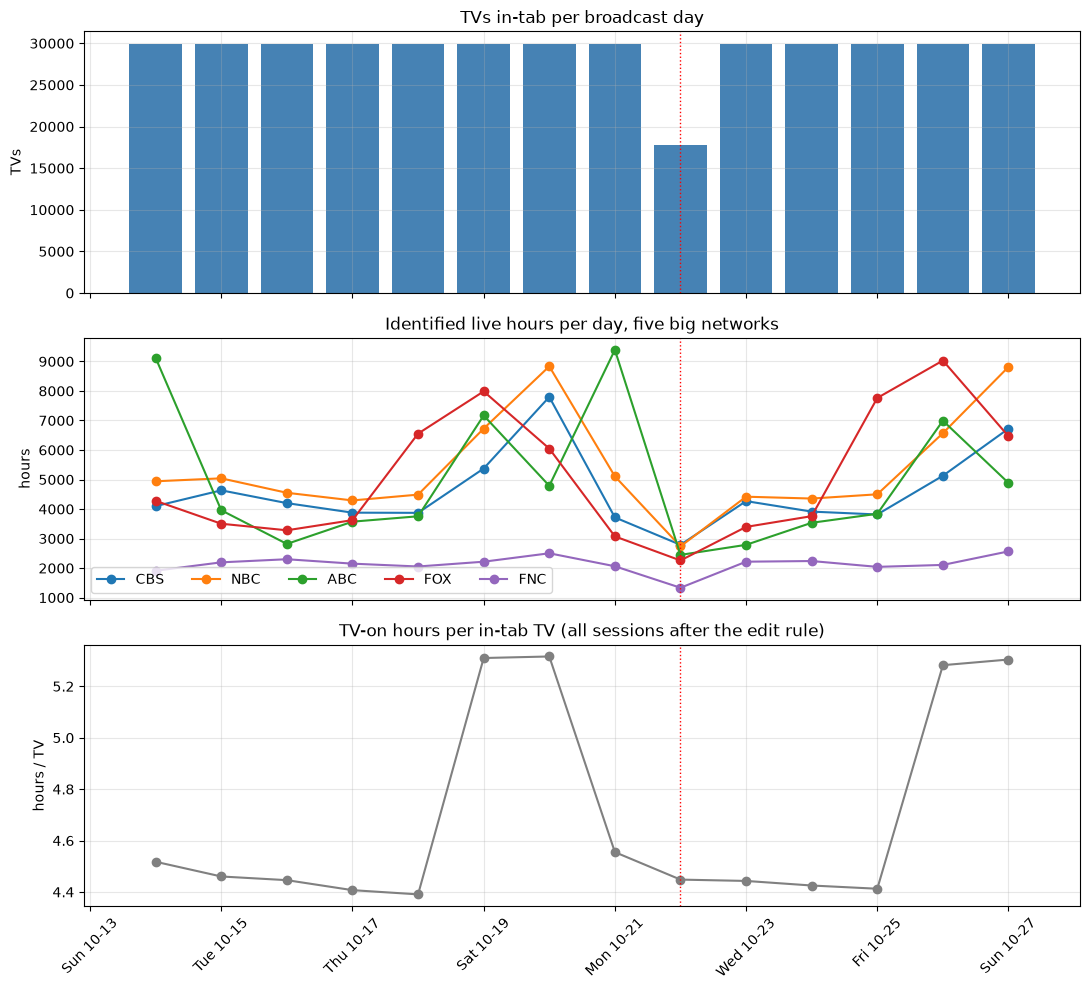

In [11]:
big_daily = (live[live["network_code"].isin(BIG)]
             .pivot_table(index="bdate", columns="network_code", values="minutes", aggfunc="sum") / 60)[BIG]
hours_per_tv = acr_ok.groupby("bdate")["minutes"].sum() / 60 / intab_tv

fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
ax[0].bar(intab_tv.index, intab_tv.values, color="steelblue")
ax[0].set_title("TVs in-tab per broadcast day")
ax[0].set_ylabel("TVs")
for net in BIG:
    ax[1].plot(big_daily.index, big_daily[net], marker="o", label=net)
ax[1].set_title("Identified live hours per day, five big networks")
ax[1].set_ylabel("hours")
ax[1].legend(ncol=5)
ax[2].plot(hours_per_tv.index, hours_per_tv.values, marker="o", color="gray")
ax[2].set_title("TV-on hours per in-tab TV (all sessions after the edit rule)")
ax[2].set_ylabel("hours / TV")
for a in ax:
    a.axvline(pd.Timestamp("2024-10-22"), color="red", ls=":", lw=1)
    a.grid(alpha=0.3)
ax[2].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %m-%d"))
plt.setp(ax[2].get_xticklabels(), rotation=45)
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [12]:
net_day = (live.groupby(["bdate", "network_code"])["minutes"].sum() / 60).sort_values(ascending=False)
spike_day, spike_net = net_day.index[0]
print("Biggest spike (date, network):", f"{spike_day:%Y-%m-%d}, {spike_net}")
print("Top network-days by identified live hours:")
display(net_day.head(6).round(0).to_frame("live hours"))
aired = programs[(programs["network_code"] == spike_net) & (programs["broadcast_date"] == spike_day)]
display(aired[["program_name", "episode_name", "start_ts", "end_ts"]])

broken = intab_tv.idxmin()
print("Broken day (date):", f"{broken:%Y-%m-%d}")
print("TVs in-tab that day:", intab_tv[broken], "of", acr["tv_id"].nunique(),
      f"({100 * (1 - intab_tv[broken] / acr['tv_id'].nunique()):.1f} % missing)")
print("Hours per in-tab TV that day:", f"{hours_per_tv[broken]:.2f}",
      "vs other weekdays:", f"{hours_per_tv[(hours_per_tv.index.day_of_week < 5) & (hours_per_tv.index != broken)].mean():.2f}")
present = tvs["tv_id"].isin(acr_ok.loc[acr_ok["bdate"] == broken, "tv_id"])
by_dma = present.groupby(tvs["dma_code"]).mean()
print("Share of each DMA's TVs present that day: min", f"{by_dma.min():.3f}", "max", f"{by_dma.max():.3f}")

Biggest spike (date, network): 2024-10-21, ABC
Top network-days by identified live hours:


,,live hours
bdate,network_code,
2024-10-21,ABC,9392.0
2024-10-14,ABC,9118.0
2024-10-26,FOX,9030.0
2024-10-20,NBC,8834.0
2024-10-27,NBC,8816.0
2024-10-19,FOX,7986.0


,program_name,episode_name,start_ts,end_ts
272,Good Morning America,"Alessia Cara, Jenny Slate, Dr. Jill Biden",2024-10-21 07:00:00,2024-10-21 09:00:00
273,Local / Syndicated Programming,NaN,2024-10-21 09:00:00,2024-10-21 11:00:00
274,The View,Tim Walz,2024-10-21 11:00:00,2024-10-21 12:00:00
275,Local / Syndicated Programming,NaN,2024-10-21 12:00:00,2024-10-21 13:00:00
276,GMA3,"Sec. Al Schmidt, Courtney Mason",2024-10-21 13:00:00,2024-10-21 14:00:00
277,General Hospital,Ep. #15573,2024-10-21 14:00:00,2024-10-21 15:00:00
278,Local / Syndicated Programming,NaN,2024-10-21 15:00:00,2024-10-21 18:30:00
279,ABC World News Tonight with David Muir,Episode 283,2024-10-21 18:30:00,2024-10-21 19:00:00
280,Local / Syndicated Programming,NaN,2024-10-21 19:00:00,2024-10-21 20:00:00
281,Who Wants to Be a Millionaire,NaN,2024-10-21 20:00:00,2024-10-21 20:15:00


Broken day (date): 2024-10-22


TVs in-tab that day: 17818 of 29940 (40.5 % missing)
Hours per in-tab TV that day: 4.45 vs other weekdays: 4.45
Share of each DMA's TVs present that day: min 0.557 max 0.630


**Answer:** The biggest spike is ABC on Monday Oct 21: Monday Night Football, Baltimore at Tampa Bay
(20:15–23:25); ABC on Monday Oct 14 (MNF again) is second. Next come the weekend sports: FOX on Saturday
Oct 26 (World Series Game 2 / college football), NBC on Sunday Oct 20 and Oct 27 (Sunday Night Football)
and FOX on Saturday Oct 19. These are real audience events: the same number of TVs, more of them on one
network for three hours.

The broken day is Tuesday Oct 22: only 17,818 of 29,940 TVs (40.5 % missing) sent any data, evenly
across all markets and all hours, while the TVs that did report watched a normal 4.4 hours. The audience
did not change; the feed lost a batch of TVs (a delivery / ingestion outage). If nobody noticed, every
daily total that day (hours, impressions, reach counts) falls by about 40 % and looks like a collapse in
viewing, and a rating computed with the full 29,940 TVs as the base would be about 40 % too low. Since the
TVs dropped at random, ratings with the day's in-tab TVs as denominator are still fine (just noisier).
So: flag it, keep it for ratings and per-TV averages with in-tab as the base, but drop it (or
re-project to the full footprint) for any totals and trends, and ask the vendor to re-deliver the lost files.

## Task 5.1 — Sampling error vs bias

In [13]:
pick = {"NFL Football": "Sunday Night Football", "Hannity": "Hannity", "Unsellable Houses": "Unsellable Houses"}
rows = []
for _, t in ref[ref["program_name"].isin(pick)].iterrows():
    p = t["hh_rating"] / 100
    d = t["broadcast_date"]
    n_tv, n_pn = intab_tv[d], intab_panel_n[d]
    tv_r = ratings.loc[ratings["network"] == t["network_code"], "TVs' HH rating"].iloc[0]
    rows.append({"telecast": pick[t["program_name"]], "date": f"{d:%Y-%m-%d}", "reference": t["hh_rating"],
                 "n TVs": n_tv, "n panel HH": n_pn,
                 "SE footprint": 100 * np.sqrt(p * (1 - p) / n_tv),
                 "SE panel": 100 * np.sqrt(p * (1 - p) / n_pn),
                 "TVs' rating - reference": tv_r - t["hh_rating"]})
se = pd.DataFrame(rows).set_index("telecast")
se["SE panel / SE footprint"] = se["SE panel"] / se["SE footprint"]
se["bias / SE footprint"] = se["TVs' rating - reference"].abs() / se["SE footprint"]
display(se.round(2))

,date,reference,n TVs,n panel HH,SE footprint,SE panel,TVs' rating - reference,SE panel / SE footprint,bias / SE footprint
telecast,,,,,,,,,
Sunday Night Football,2024-10-27,33.14,29940,3898,0.27,0.75,-11.89,2.77,43.71
Hannity,2024-10-16,2.30,29940,3867,0.09,0.24,-1.48,2.78,17.03
Unsellable Houses,2024-10-16,3.69,29940,3867,0.11,0.30,-1.59,2.78,14.62


**Answer:** With 29,940 TVs instead of ~3,900 panel homes the sampling error is about 2.8 times smaller
(√(n ratio)): 0.27 vs 0.75 points for Sunday Night Football, 0.09 vs 0.24 for Hannity, 0.11 vs 0.30 for
Unsellable Houses. But the TVs' ratings miss the reference by −11.9, −1.5 and −1.6 points: 15–44 times
their own SE. The bias is far bigger than the sampling error, and more data does not shrink it: a feed
ten times bigger would give the same wrong number with a smaller error bar. Sampling error falls with
√n; bias comes from who is in the sample and what is measured (one set, skewed homes) and stays. A big
sample is precise, not accurate.

## Task 5.2 — Answer to the planner
**Answer:** From this feed, Sunday Night Football (Dallas at San Francisco, NBC, Oct 27) reached 21.2 %
of the smart TVs in-tab that day, but please do not put that in front of the client as a household
rating: the currency figure is 33.1, and our number is about a third too low. The feed sees one smart TV
per home, so homes that watched on another set count as non-viewers; it cannot see who was in the room,
viewing it could not recognize, homes that never opted in, or the 35 % of TVs we could not match to a
household, and its homes are richer, less often elderly and more Western than the US. The tiny sampling error (±0.3
points) is misleading, because the error that matters is this bias, which more TVs do not fix. For the
presentation tomorrow, use the currency rating of 33.1; the feed is fine for direction, e.g. minute-by-minute
shape or market splits. Before using it for planning we would need weights that project it to US homes
(by income, age, region; Lab 4), a calibration to the panel for the missing sets, a better household match,
and the vendor's fix of data outages like Oct 22.

## Bonus

In [14]:
snf = ref[ref["program_name"] == "NFL Football"].iloc[0]
day = snf["broadcast_date"]
dw_day = daily_weights[daily_weights["broadcast_date"] == day].set_index("respondent_id")["weight"]
dw_rl = daily_weights[(daily_weights["broadcast_date"] == day) & daily_weights["resp_type"].isin(["R", "L"])]
age_rl = dw_rl["respondent_id"].map(age)
a2554_ids = dw_rl.loc[age_rl.between(25, 54), "respondent_id"]

pv_day = viewings[viewings["resp_type"].isin(["H", "R", "L"])]
w_ids = watchers(pv_day, snf["network_code"], snf["start_ts"], snf["end_ts"], "respondent_id")
hh_w = [i for i in w_ids if i % 100 == 0]
p_w = [i for i in w_ids if i in set(a2554_ids)]
vpvh = dw_day.reindex(p_w).sum() / dw_day.reindex(hh_w).sum()

us_hh = daily_weights.loc[(daily_weights["broadcast_date"] == day) & (daily_weights["resp_type"] == "H"), "weight"].sum()
us_a2554 = dw_rl.loc[age_rl.between(25, 54), "weight"].sum()
tv_hh_rating = ratings.loc[ratings["network"] == "NBC", "TVs' HH rating"].iloc[0]
a2554_rating = tv_hh_rating * vpvh * us_hh / us_a2554
panel_hh_rating = 100 * dw_day.reindex(hh_w).sum() / us_hh
print("Panel HH rating (check):", f"{panel_hh_rating:.1f}")
print("US TV households (M):", f"{us_hh / 1e6:.1f}", "| US A25-54 persons (M):", f"{us_a2554 / 1e6:.1f}")
print("VPVH A25-54:", f"{vpvh:.3f}")
print("A25-54 rating (persons):", f"{a2554_rating:.1f}")
print("Same with the reference HH rating instead:", f"{snf['hh_rating'] * vpvh * us_hh / us_a2554:.1f}")

Panel HH rating (check): 34.2
US TV households (M): 125.8 | US A25-54 persons (M): 123.7
VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
Same with the reference HH rating instead: 17.3


**Answer:** In the panel, every 100 homes watching Sunday Night Football held about 51 A25-54 viewers
(VPVH 0.513). Applied to the TVs' household rating of 21.2, with 125.8 M TV homes and 123.7 M A25-54
persons, this gives an A25-54 rating of 11.1 (with the reference household rating 33.1 it would be 17.3,
so most of the error comes from the biased household number). The method assumes that a viewing home in the
footprint holds as many A25-54 viewers as a viewing home in the panel, i.e. the same household size, age mix
and co-viewing, and that the TVs' household rating is right. Neither holds here: the footprint has more
35-64 and fewer 65+ heads of household (more A25-54 per home), and its household rating misses other sets,
so the estimate carries all the bias of Tasks 2–3.